## HT2026-DA631E-TS056
## Mini Project 1
### Author: Nancy Truong
#### Final test evaluation

Refit the selected model family on all permitted development data, transform the 2021 test set with that same fitted pipeline, evaluate once and save atifacts.

On the held-out 2021 test period, the selected HGB model achieved an **unannualized spread Sharpe of 0.0867**, compared with a mean validation Sharpe of **0.2359**. Performance was therefore weaker on unseen data. The mean daily Spearman IC of **0.003454** indicates only a weak positive association between predicted and actual stock rankings.

Return-prediction accuracy was also limited. The MAE of **0.015337** corresponds to an average absolute error of approximately **1.53 percentage points**. The MSE of **0.000495** corresponds to an RMSE of approximately **2.22 percentage points**. The negative $R^2$ of **−0.0261** means that squared prediction error was approximately **2.61% greater than the test-mean reference used by this metric**.

Performance varied considerably over time. Quarterly spread Sharpe was positive in Q1, Q2, and Q3 (**0.1893, 0.1453, and 0.1516**), but became negative in the available Q4 period (**−0.2038**). Mean daily IC was also negative in October and November, showing that ranking performance deteriorated during these months. December contains only three observations of daily IC, so its slightly positive mean provides little evidence of recovery.

The positive aggregate spread score therefore conceals a late-period reversal. These results suggest weak and unstable predictive performance; they do not establish consistent trading profitability, particularly because transaction costs and execution constraints are not included.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import sys
import json
import platform
import time
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def find_project_root(start: Path = Path.cwd()) -> Path:
    """Find the parent directory containing src/data.py."""
    for candidate in (start, *start.parents):
        if (candidate / "src" / "data.py").is_file():
            return candidate

    raise FileNotFoundError("Could not find src/data.py")


PROJECT_ROOT = Path("/content/drive/MyDrive/Project_SupervisedLearning_1")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from config import ProjectConfig, ProjectPaths

config = ProjectConfig()
paths = ProjectPaths(PROJECT_ROOT)
paths.ensure_output_dirs

from modeling import (
    build_model_pipeline
    ,chronological_split
    ,development_and_test_split
    ,make_xy
    ,save_json
    ,select_recent_dates
    ,evaluate_predictions
    ,walk_forward_split
    ,make_fold_metric_record
)
from features import (
    infer_feature_columns
)


print("Project root:", PROJECT_ROOT)
print("Imported load_data successfully")

print("Imported libraries sucessfully! yay")

Project root: /content/drive/MyDrive/Project_SupervisedLearning_1
Imported load_data successfully
Imported libraries sucessfully! yay


In [ ]:
selected_path = paths.reports / "selected_model.json"
if not selected_path.is_file():
    raise FileNotFoundError("Run notebook 04 and save the model family first")

selection = json.loads(selected_path.read_text(encoding='utf-8'))
selected_model = selection['selected_model']
FAST_MODE = bool(selection['fast_mode'])
print(f"Selected model: {selected_model}; FAST_MODE={FAST_MODE}")

Selected model: hist_gradient_boosting; FAST_MODE=False


### Rebuild development data (train + validation) and test sets

Train and validation datasets are now combined becuase the model is fixed. Use the combined set to train and no longer need a purge between train and validation.

The final two development dates are purged because their labels cross into the 2021 test period

In [ ]:
features_table = pd.read_parquet(paths.processed / "features_table.parquet")
numeric_features, categorical_features = infer_feature_columns(features_table)
development, test, purged_dates = development_and_test_split(features_table, config)

split_summary = pd.DataFrame({
    'split': ["development","test"]
    ,'rows': [len(development), len(test)]
    ,'dates': [development['Date'].nunique(), test['Date'].nunique()]
    ,'date_min': [development['Date'].min(), test['Date'].min()]
    ,'date_max': [development['Date'].max(), test['Date'].max()]
}).set_index('split')
display(split_summary)

print("Purged before test: ", [str(date.date()) for date in purged_dates])

,rows,dates,date_min,date_max
split,,,,
development,1876293,974,2017-01-04,2020-12-28
test,452000,226,2021-01-04,2021-12-03


Purged before test:  ['2020-12-29', '2020-12-30']


### Fit on development and transform test

In [ ]:
X_development, y_development = make_xy(
    development, numeric_features, categorical_features
)
X_test, y_test = make_xy(
    test, numeric_features, categorical_features
)

pipeline = build_model_pipeline(
    model_name=selected_model,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_seed=config.random_seed,
    fast_mode=FAST_MODE,
    model_params={
        **selection["params"],
        "max_iter": 100,
    },
)

started = time.perf_counter()
pipeline.fit(X_development, y_development)
fit_seconds = time.perf_counter() - started

test_predictions = pipeline.predict(X_test)

assert len(test_predictions) == len(test)
assert np.isfinite(test_predictions).all()

print(f"Final fit completed in {fit_seconds:.1f} seconds")

Final fit completed in 145.7 seconds


### Open test result

Interpret ranking metrics

In [ ]:
test_metrics, test_ranked, test_daily_ic, test_daily_spread_return = evaluate_predictions(
    df = test
    ,predictions = test_predictions
    ,config=config
    ,strict_portfolio_size = True
)
test_metrics.loc['FinalFitSeconds'] = fit_seconds

display(test_metrics.to_frame())

,value
MAE,0.015230
MSE,0.000489
R2,-0.013835
MeanDailyIC,0.003277
MedianDailyIC,0.004397
MeanDailySpreadReturn,0.137978
MedianDailySpreadReturn,0.213696
DailySpreadReturnStd,1.751186
SpreadSharpeRatio,0.078791
FinalFitSeconds,145.715543


In [ ]:
rank_check = test_ranked.groupby('Date')['Rank'].agg(['min','max','nunique','size'])
assert rank_check['min'].eq(0).all()
assert rank_check['nunique'].eq(rank_check['size']).all()
assert rank_check['max'].eq(rank_check['size'] - 1).all()

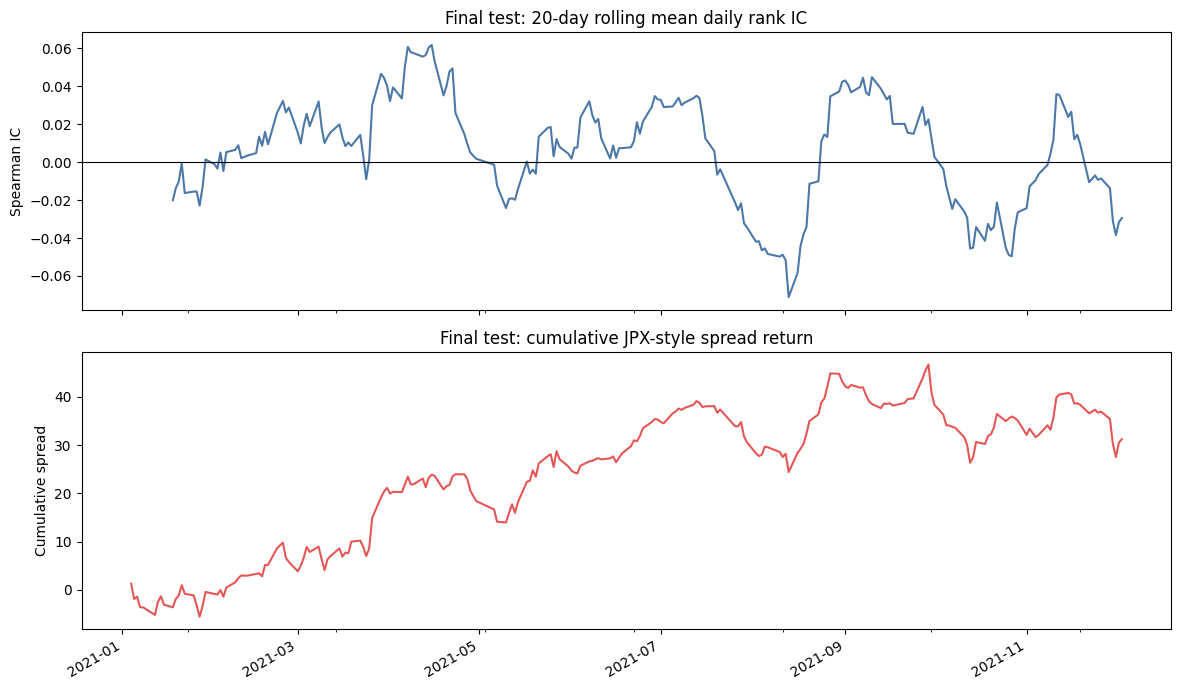

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
test_daily_ic.rolling(20, min_periods=10).mean().plot(ax=axes[0], color="#4C78A8")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Final test: 20-day rolling mean daily rank IC")
axes[0].set_ylabel("Spearman IC")

test_daily_spread_return.cumsum().plot(ax=axes[1], color="#E45756")
axes[1].set_title("Final test: cumulative JPX-style spread return")
axes[1].set_ylabel("Cumulative spread")
plt.tight_layout()
plt.show()

In [ ]:
monthly_ic = test_daily_ic.groupby(test_daily_ic.index.to_period("M")).agg(["mean", "median", "count"])
quarterly_spread = test_daily_spread_return.groupby(test_daily_spread_return.index.to_period("Q")).agg(
    ["mean", "std", "sum", "count"]
)
quarterly_spread["Sharpe"] = quarterly_spread["mean"] / quarterly_spread["std"]
display(monthly_ic)
display(quarterly_spread)

,mean,median,count
2021-01,0.001420,-0.001040,19
2021-02,0.008851,0.000829,18
2021-03,0.042800,0.057807,23
2021-04,-0.000506,-0.000070,21
2021-05,0.012854,0.011926,18
2021-06,0.026525,0.031981,22
2021-07,-0.034396,-0.028685,20
2021-08,0.031014,0.014042,21
2021-09,0.012662,0.021401,20
2021-10,-0.034354,-0.037897,21


,mean,std,sum,count,Sharpe
2021Q1,0.351714,1.885141,21.102817,60,0.186572
2021Q2,0.232449,1.512320,14.179393,61,0.153704
2021Q3,0.092299,1.711413,5.630233,61,0.053931
2021Q4,-0.221123,1.918552,-9.729393,44,-0.115255


In [ ]:
def plot_stock_rank_history(
    predictions, security_code=None, *, portfolio_size=200,
    split_label="2021 test",
):
    """Compare one stock's predicted/actual daily percentile ranks.

    All-stock ranks are computed BEFORE selecting the stock. Default stock is
    the alphabetically first code among stocks with maximum date coverage,
    chosen without using returns or model performance.
    """
    data = _prepare(predictions, portfolio_size)
    if security_code is None:
        coverage = data.groupby("SecuritiesCode")["Date"].nunique()
        security_code = sorted(
            coverage.index[coverage.eq(coverage.max())].tolist()
        )[0]
    history = data.loc[
        data["SecuritiesCode"].eq(str(security_code))
    ].sort_values("Date")
    if history.empty:
        raise ValueError(f"Security {security_code} is absent from predictions.")
    with plt.rc_context({"font.size": 10, "figure.facecolor": "white"}):
        fig, ax = plt.subplots(figsize=(13, 4.8))
        ax.plot(
            history["Date"], history["ActualPercentile"], color="#D47B28",
            alpha=0.45, linewidth=0.8, marker=".", markersize=3,
            label="Actual daily return rank",
        )
        ax.plot(
            history["Date"], history["PredictedPercentile"], color="#2266A7",
            linewidth=1.4, label="Predicted daily rank",
        )
        upper = 100 * (1 - portfolio_size / history["UniverseSize"])
        lower = 100 * portfolio_size / history["UniverseSize"]
        ax.plot(
            history["Date"], upper, "--", color="#718096", linewidth=0.8,
            label=f"Top/bottom {portfolio_size} cutoffs (approximate with ties)",
        )
        ax.plot(history["Date"], lower, "--", color="#718096", linewidth=0.8)
        ax.set(
            ylim=(0, 100), xlabel="Prediction date",
            ylabel="Daily percentile rank (higher = better)",
            title=f"{split_label} · stock {security_code} · ranking over time",
        )
        locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.legend(frameon=False, loc="upper left", fontsize=9)
        _style(ax)
        fig.tight_layout()
    return fig, history.reset_index(drop=True)

In [ ]:


def _prepare(predictions, portfolio_size):
    required = {"Date", "SecuritiesCode", "Prediction", "Target"}
    missing = required.difference(predictions.columns)
    if missing:
        raise ValueError(f"Missing prediction columns: {sorted(missing)}")
    if not isinstance(portfolio_size, (int, np.integer)) or portfolio_size < 1:
        raise ValueError("portfolio_size must be a positive integer.")
    data = predictions.copy()
    if data.empty or data[["Date", "SecuritiesCode"]].isna().any().any():
        raise ValueError("Prediction data must be nonempty with valid dates/codes.")
    if pd.api.types.is_numeric_dtype(data["Date"]):
        raise ValueError("Parse numeric date codes explicitly before plotting.")
    data["Date"] = pd.to_datetime(data["Date"], errors="raise")
    data["SecuritiesCode"] = data["SecuritiesCode"].astype(str)
    if data.duplicated(["Date", "SecuritiesCode"]).any():
        raise ValueError("Select one model/split: duplicate stock-date rows found.")
    for column in ["Prediction", "Target"]:
        data[column] = pd.to_numeric(data[column], errors="raise")
        if not np.isfinite(data[column].to_numpy(dtype=float)).all():
            raise ValueError(f"{column} contains nonfinite values.")
    data = data.sort_values(
        ["Date", "Prediction", "SecuritiesCode"],
        ascending=[True, False, True], kind="mergesort",
    ).reset_index(drop=True)
    group = data.groupby("Date", sort=False)
    n = group["Target"].transform("size")
    if (n < 2 * portfolio_size).any():
        raise ValueError("Use full daily cross-sections with at least 2*K stocks.")
    if "UniverseSize" in data and not data["UniverseSize"].eq(n).all():
        raise ValueError("Prediction rows do not match the recorded universe size.")
    data["UniverseSize"] = n
    data["PredictedPosition"] = group.cumcount() + 1
    if "Rank" in data and not data["Rank"].eq(
        data["PredictedPosition"] - 1
    ).all():
        raise ValueError("Stored Rank differs from the evaluator's tie ordering.")
    for column, prefix in [("Prediction", "Predicted"), ("Target", "Actual")]:
        average_rank = group[column].rank(method="average", ascending=True)
        data[f"{prefix}Percentile"] = 100 * (average_rank - 0.5) / n
        if prefix == "Actual":
            data["ActualPosition"] = n + 1 - average_rank
    data["Side"] = np.select(
        [data["PredictedPosition"].le(portfolio_size),
         data["PredictedPosition"].gt(n - portfolio_size)],
        ["Long", "Short"], default="Middle",
    )
    return data


def _style(ax):
    ax.set_axisbelow(True)
    ax.grid(alpha=0.18)
    ax.spines[["top", "right"]].set_visible(False)


def plot_stock_rank_snapshot(
    predictions, date=None, *, portfolio_size=200,
    stocks_per_side=6, split_label="2021 test",
):
    """Show all stocks on one date plus an outcome-independent tail selection.

    Default date is the middle AVAILABLE date, not the best-performing date.
    Right panel selects the strongest predicted longs/shorts before looking at
    actual outcomes. Returned rows include their realized return and positions.
    """
    if not 1 <= stocks_per_side <= portfolio_size:
        raise ValueError("stocks_per_side must be between 1 and portfolio_size.")
    data = _prepare(predictions, portfolio_size)
    dates = data["Date"].drop_duplicates().sort_values()
    chosen_date = (
        dates.iloc[len(dates) // 2] if date is None else pd.Timestamp(date)
    )
    day = data.loc[data["Date"].eq(chosen_date)].copy()
    if day.empty:
        raise ValueError(f"No prediction rows on {chosen_date.date()}.")
    if day["Prediction"].nunique() < 2 or day["Target"].nunique() < 2:
        ic_text = "IC undefined (constant scores or targets)"
    else:
        ic = day["PredictedPercentile"].corr(day["ActualPercentile"])
        ic_text = f"Daily Spearman IC = {ic:.4f}"

    selected = pd.concat([
        day.loc[day["Side"].eq("Long")].head(stocks_per_side),
        day.loc[day["Side"].eq("Short")].tail(stocks_per_side),
    ]).sort_values("PredictedPosition")

    with plt.rc_context({"font.size": 10, "figure.facecolor": "white"}):
        fig, axes = plt.subplots(
            1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1, 1.1]}
        )
        colors = {"Middle": "#C4CBD2", "Long": "#2266A7", "Short": "#D47B28"}
        for side in ["Middle", "Long", "Short"]:
            rows = day.loc[day["Side"].eq(side)]
            axes[0].scatter(
                rows["PredictedPercentile"], rows["ActualPercentile"],
                color=colors[side], s=10 if side == "Middle" else 20,
                alpha=0.3 if side == "Middle" else 0.65,
                label=side if side == "Middle" else f"{side} {portfolio_size}",
                edgecolors="none",
            )
        axes[0].plot([0, 100], [0, 100], "--", color="#38424D",
                     linewidth=1, label="Perfect ordering")
        axes[0].set(
            xlim=(0, 100), ylim=(0, 100),
            xlabel="Predicted percentile (higher = better)",
            ylabel="Actual return percentile (higher = better)",
            title=f"All {len(day):,} stocks on one date\n{ic_text}",
        )
        axes[0].legend(frameon=False, fontsize=9, loc="upper left")

        positions = np.arange(len(selected))
        axes[1].hlines(
            positions, selected["PredictedPercentile"],
            selected["ActualPercentile"], color="#ADB5BE", linewidth=1.8,
        )
        axes[1].scatter(
            selected["PredictedPercentile"], positions, color="#2266A7",
            marker="D", s=48, label="Predicted",
        )
        axes[1].scatter(
            selected["ActualPercentile"], positions, color="#D47B28",
            s=48, label="Actual",
        )
        labels = []
        for _, row in selected.iterrows():
            name = (
                f" · {str(row['Name'])[:20]}"
                if "Name" in selected and pd.notna(row["Name"]) else ""
            )
            labels.append(f"{row['SecuritiesCode']}{name} ({row['Side']})")
        axes[1].set(
            xlim=(-2, 102), yticks=positions, yticklabels=labels,
            xlabel="Rank percentile (higher = better)",
            title="Where did the selected stocks actually finish?",
        )
        axes[1].invert_yaxis()
        axes[1].legend(frameon=False, loc="lower right")
        for ax in axes:
            _style(ax)
        fig.suptitle(
            f"{split_label} · {chosen_date:%Y-%m-%d} · predicted vs actual ranks",
            fontsize=15, fontweight="bold",
        )
        fig.text(
            0.5, 0.025,
            "Ranks are computed using every eligible stock on this date. "
            "Percentiles preserve ties; portfolio positions break prediction ties "
            "by security code. This snapshot is descriptive.",
            ha="center", fontsize=9, color="#4E5967",
        )
        fig.tight_layout(rect=(0, 0.08, 1, 0.9))

    columns = [
        "Date", "SecuritiesCode", "Side", "PredictedPosition",
        "ActualPosition", "PredictedPercentile", "ActualPercentile", "Target",
    ]
    if "Name" in selected:
        columns.insert(2, "Name")
    return fig, selected[columns].reset_index(drop=True)


def plot_stock_rank_history(
    predictions, security_code=None, *, portfolio_size=200,
    split_label="2021 test",
):
    """Compare one stock's predicted/actual daily percentile ranks.

    All-stock ranks are computed BEFORE selecting the stock. Default stock is
    the alphabetically first code among stocks with maximum date coverage,
    chosen without using returns or model performance.
    """
    data = _prepare(predictions, portfolio_size)
    if security_code is None:
        coverage = data.groupby("SecuritiesCode")["Date"].nunique()
        security_code = sorted(
            coverage.index[coverage.eq(coverage.max())].tolist()
        )[0]
    history = data.loc[
        data["SecuritiesCode"].eq(str(security_code))
    ].sort_values("Date")
    if history.empty:
        raise ValueError(f"Security {security_code} is absent from predictions.")
    with plt.rc_context({"font.size": 10, "figure.facecolor": "white"}):
        fig, ax = plt.subplots(figsize=(13, 4.8))
        ax.plot(
            history["Date"], history["ActualPercentile"], color="#D47B28",
            alpha=0.45, linewidth=0.8, marker=".", markersize=3,
            label="Actual daily return rank",
        )
        ax.plot(
            history["Date"], history["PredictedPercentile"], color="#2266A7",
            linewidth=1.4, label="Predicted daily rank",
        )
        upper = 100 * (1 - portfolio_size / history["UniverseSize"])
        lower = 100 * portfolio_size / history["UniverseSize"]
        ax.plot(
            history["Date"], upper, "--", color="#718096", linewidth=0.8,
            label=f"Top/bottom {portfolio_size} cutoffs (approximate with ties)",
        )
        ax.plot(history["Date"], lower, "--", color="#718096", linewidth=0.8)
        ax.set(
            ylim=(0, 100), xlabel="Prediction date",
            ylabel="Daily percentile rank (higher = better)",
            title=f"{split_label} · stock {security_code} · ranking over time",
        )
        locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.legend(frameon=False, loc="upper left", fontsize=9)
        _style(ax)
        fig.tight_layout()
    return fig, history.reset_index(drop=True)


def plot_model_rank_deciles(
    predictions_by_model, *, portfolio_size=200, split_label="2021 test",
):
    """Compare full-data, equal-date-weighted rank-decile returns.

    Input is a dict mapping model names to FULL prediction DataFrames. Comparisons
    require identical stock-date rows. Decile 1 is lowest predicted score and
    decile 10 highest. Score ties stay together and can leave uneven/missing bins.
    This descriptive plot has no significance or confidence-interval claims.
    """
    if not predictions_by_model:
        raise ValueError("Supply at least one model prediction table.")
    profiles = []
    reference_keys = None
    reference_targets = None
    for model_name, predictions in predictions_by_model.items():
        data = _prepare(predictions, portfolio_size)
        keys = pd.MultiIndex.from_frame(
            data[["Date", "SecuritiesCode"]].sort_values(
                ["Date", "SecuritiesCode"]
            )
        )
        if reference_keys is None:
            reference_keys = keys
            reference_targets = data.sort_values(
                ["Date", "SecuritiesCode"]
            )["Target"].to_numpy()
        elif not keys.equals(reference_keys):
            raise ValueError("Compare models on identical stock-date rows.")
        elif not np.array_equal(
            data.sort_values(["Date", "SecuritiesCode"])["Target"].to_numpy(),
            reference_targets,
        ):
            raise ValueError("Compared models must use identical actual targets.")
        data["Decile"] = np.ceil(
            data["PredictedPercentile"] / 10
        ).clip(1, 10).astype(int)
        daily = data.groupby(["Date", "Decile"], sort=True)["Target"].mean()
        profile = daily.groupby("Decile").agg(
            MeanActualReturn="mean", Dates="size"
        ).reindex(range(1, 11))
        profile["Model"] = model_name
        profiles.append(profile.reset_index())
    profile = pd.concat(profiles, ignore_index=True)

    with plt.rc_context({"font.size": 10, "figure.facecolor": "white"}):
        fig, ax = plt.subplots(figsize=(9, 5))
        for model_name, rows in profile.groupby("Model", sort=False):
            ax.plot(
                rows["Decile"], 100 * rows["MeanActualReturn"],
                marker="o", linewidth=1.8, label=model_name,
            )
        ax.axhline(0, color="#718096", linewidth=0.8)
        ax.set(
            xticks=range(1, 11),
            xlabel="Predicted score decile (1 lowest; 10 highest)",
            ylabel="Mean actual target return (%)",
            title=f"{split_label} · do higher scores identify higher returns?",
        )
        ax.legend(frameon=False)
        _style(ax)
        fig.text(
            0.5, 0.015,
            "Average within each date/decile, then across dates. Ties stay together. "
            "Bucket means differ from the weighted JPX spread score.",
            ha="center", fontsize=9, color="#4E5967",
        )
        fig.tight_layout(rect=(0, 0.06, 1, 1))
    return fig, profile



In [ ]:
import matplotlib.dates as mdates

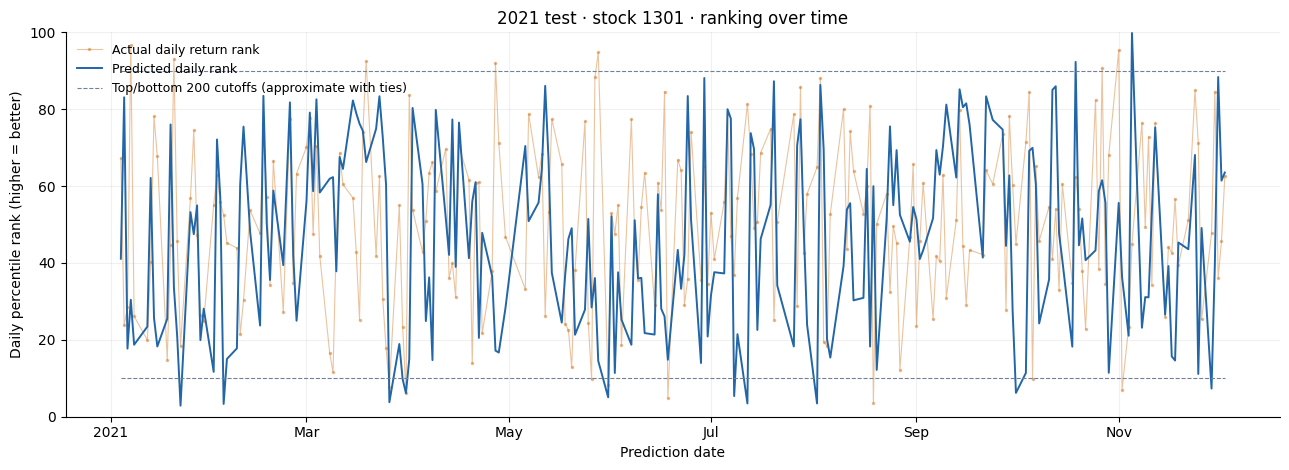

In [ ]:
fig, stock_history = plot_stock_rank_history(test_ranked)
plt.show()

In [ ]:
for file in REPORTS_DIR.glob("*.csv"):
    df = pd.read_csv(file)

    if any("baseline" in col.lower() for col in df.columns):
        print(f"\n{file.name}")
        print(df.tail(10).to_string(index=False))


tuning_stage2_folds.csv
            model_name     fold_name train_start  train_end validation_start validation_end           train_purged_dates  train_full_rows  train_after_purged_rows  validation_rows  train_full_dates  train_after_purged_dates  validation_dates  training_seconds      MAE      MSE        R2  MeanDailyIC  MedianDailyIC  MeanDailySpreadReturn  MedianDailySpreadReturn  DailySpreadReturnStd  SpreadSharpeRatio  Train_MAE  Train_MSE  Train_R2  Train_MeanDailyIC  Train_MedianDailyIC  Train_MeanDailySpreadReturn  Train_MedianDailySpreadReturn  Train_DailySpreadReturnStd  Train_SpreadSharpeRatio candidate_name  is_baseline                                                                                                                                                  params_json  n_iter  SharpeGap  ValidICCoverage  ValidICDates      validation_purged_dates
hist_gradient_boosting validate_2019  2017-01-04 2018-12-28       2019-01-04     2019-12-26 ['2018-12-27', '2018-12-28'] 

#Random forest evaluation

In [ ]:
features_table = pd.read_parquet(
    PROJECT_ROOT / "data" / "processed" / "features_table.parquet"
)

In [ ]:
from scipy.stats import spearmanr
from pathlib import Path

PRED_DIR = Path(
    "/content/drive/MyDrive/Project_SupervisedLearning_1/reports/rf_predictions"
)

predictions = pd.concat(
    [
        pd.read_parquet(
            PRED_DIR / f"rf_validation_{year}_with_ids.parquet"
        )
        for year in [2018, 2019, 2020]
    ],
    ignore_index=True
)

predictions["Date"] = pd.to_datetime(predictions["Date"])
predictions["Year"] = predictions["Date"].dt.year

print("Total rows:", len(predictions))
print(predictions.groupby("Year").size())

Total rows: 1416806
Year
2018    467671
2019    468295
2020    480840
dtype: int64


##Precision@200 — Yearly, Monthly and Daily Analysis

,MeanPrecision@200,TradingDays
Year,,
2018,0.1741,245
2019,0.1404,241
2020,0.1574,243


,MeanPrecision@200,StdPrecision@200,TradingDays
YearMonth,,,
2018-01,0.1816,0.0634,19
2018-02,0.2032,0.0671,19
2018-03,0.1657,0.0717,21
2018-04,0.1315,0.0400,20
2018-05,0.2014,0.0678,21
2018-06,0.1907,0.0871,21
2018-07,0.1629,0.0751,21
2018-08,0.2120,0.0759,23
2018-09,0.1583,0.0615,18


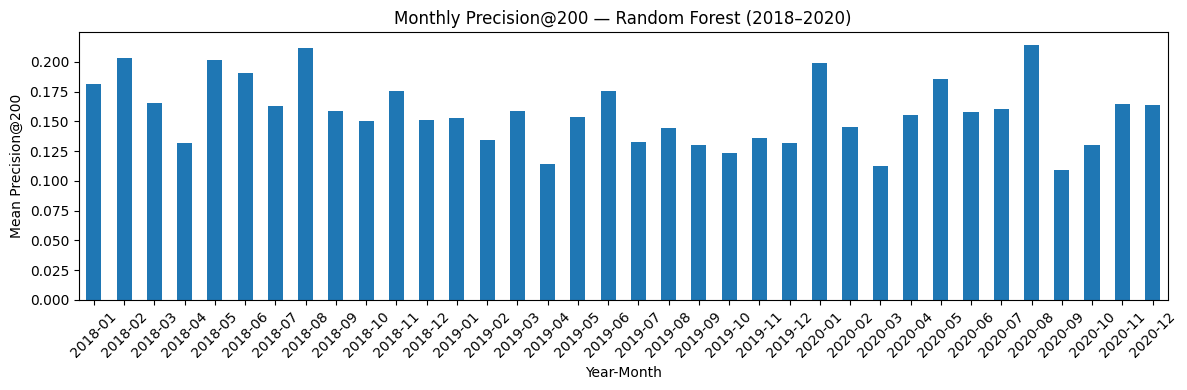

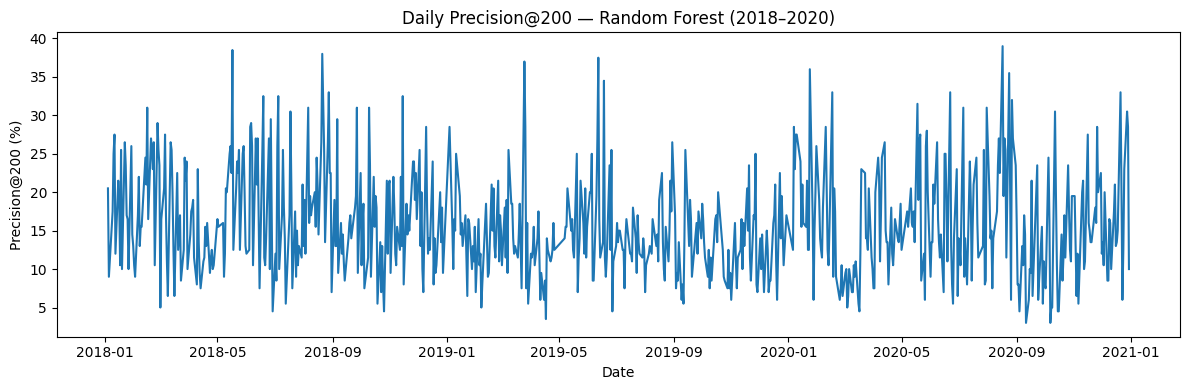

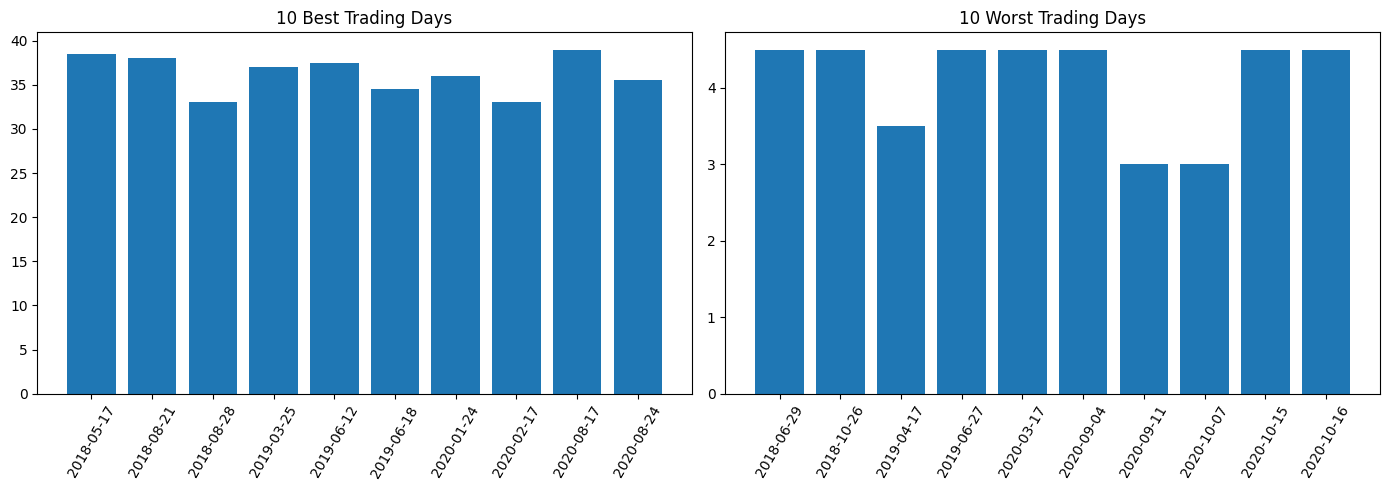

In [ ]:
precision_results = []
daily_precision = []

for year, year_data in predictions.groupby("Year"):
    for date, day in year_data.groupby("Date"):
        if len(day) < 200:
            continue

        predicted_top = set(
            day.nlargest(200, "Prediction")["SecuritiesCode"]
        )
        actual_top = set(
            day.nlargest(200, "Target")["SecuritiesCode"]
        )

        score = len(predicted_top & actual_top) / 200

        daily_precision.append({
            "Date": date,
            "Year": year,
            "Precision@200": score
        })

daily_precision_df = pd.DataFrame(daily_precision)
daily_precision_df["YearMonth"] = (
    pd.to_datetime(daily_precision_df["Date"]).dt.to_period("M")
)

# Yearly summary
yearly_precision = (
    daily_precision_df.groupby("Year")["Precision@200"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "MeanPrecision@200", "count": "TradingDays"})
)

display(yearly_precision.round(4))

# Monthly summary
monthly_precision = (
    daily_precision_df.groupby("YearMonth")["Precision@200"]
    .agg(["mean", "std", "count"])
    .rename(columns={
        "mean": "MeanPrecision@200",
        "std": "StdPrecision@200",
        "count": "TradingDays"
    })
)

display(monthly_precision.round(4))

monthly_precision["MeanPrecision@200"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Monthly Precision@200 — Random Forest (2018–2020)",
    ylabel="Mean Precision@200",
    xlabel="Year-Month",
    rot=45
)

plt.tight_layout()
plt.show()

# Daily Precision@200 across all years
plt.figure(figsize=(12, 4))
plt.plot(
    daily_precision_df["Date"],
    daily_precision_df["Precision@200"] * 100
)
plt.title("Daily Precision@200 — Random Forest (2018–2020)")
plt.xlabel("Date")
plt.ylabel("Precision@200 (%)")
plt.tight_layout()
plt.show()

# Best and worst 10 trading days across all years
best10 = daily_precision_df.nlargest(10, "Precision@200").sort_values("Date")
worst10 = daily_precision_df.nsmallest(10, "Precision@200").sort_values("Date")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(best10["Date"].dt.strftime("%Y-%m-%d"),
            best10["Precision@200"] * 100)
axes[0].set_title("10 Best Trading Days")
axes[0].tick_params(axis="x", rotation=60)

axes[1].bar(worst10["Date"].dt.strftime("%Y-%m-%d"),
            worst10["Precision@200"] * 100)
axes[1].set_title("10 Worst Trading Days")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

##Prepare Prediction Errors and Market Feature Groups — 2018–2020

In [ ]:
analysis_years = []

for year in [2018, 2019, 2020]:
    saved = pd.read_parquet(
        PRED_DIR / f"rf_validation_{year}_with_ids.parquet"
    )

    saved["Date"] = pd.to_datetime(saved["Date"])

    # Add the matching historical features
    features = features_table[
        pd.to_datetime(features_table["Date"]).between(
            f"{year}-01-01", f"{year}-12-31"
        )
    ][
        ["Date", "SecuritiesCode", "Momentum20Days",
         "Volatility20Days", "Volatility60Days"]
    ].copy()

    features["Date"] = pd.to_datetime(features["Date"])

    analysis = saved.merge(
        features,
        on=["Date", "SecuritiesCode"],
        how="left",
        validate="one_to_one",
        suffixes=("", "_feature"),
    )

    # Keep saved feature values if present; otherwise use merged features
    for col in ["Momentum20Days", "Volatility20Days", "Volatility60Days"]:
        feature_col = f"{col}_feature"
        if feature_col in analysis.columns:
            if col in analysis.columns:
                analysis[col] = analysis[col].fillna(analysis[feature_col])
                analysis.drop(columns=[feature_col], inplace=True)
            else:
                analysis.rename(columns={feature_col: col}, inplace=True)

    analysis["Year"] = year
    analysis["AbsoluteError"] = (
        analysis["Target"] - analysis["Prediction"]
    ).abs()

    analysis_years.append(analysis)

analysis_all = pd.concat(analysis_years, ignore_index=True)

print("Total rows:", len(analysis_all))
print("Rows by year:")
print(analysis_all.groupby("Year").size())
print("Missing momentum:", f"{analysis_all['Momentum20Days'].isna().mean():.2%}")
print("Missing volatility:", f"{analysis_all['Volatility20Days'].isna().mean():.2%}")

analysis_all.to_parquet(
    PRED_DIR / "rf_analysis_all_years.parquet",
    index=False
)

print("Saved combined analysis dataset.")

Total rows: 1416806
Rows by year:
Year
2018    467671
2019    468295
2020    480840
dtype: int64
Missing momentum: 0.11%
Missing volatility: 0.11%
Saved combined analysis dataset.


##Prediction Error and Ranking Quality by Momentum and Volatility — 2018–2020

In [ ]:
from scipy.stats import spearmanr

group_results = []
daily_ic_results = []

for year in [2018, 2019, 2020]:
    year_data = analysis_all[analysis_all["Year"] == year].copy()

    # Split momentum and volatility into five groups for each year
    year_data["MomentumGroup"] = pd.qcut(
        year_data["Momentum20Days"],
        q=5,
        labels=["Lowest", "Low", "Medium", "High", "Highest"],
        duplicates="drop"
    )

    year_data["VolatilityGroup"] = pd.qcut(
        year_data["Volatility20Days"],
        q=5,
        labels=["Lowest", "Low", "Medium", "High", "Highest"],
        duplicates="drop"
    )

    # MAE by momentum group
    for group, data in year_data.groupby("MomentumGroup", observed=True):
        group_results.append({
            "Year": year,
            "Type": "Momentum",
            "Group": str(group),
            "Stocks": len(data),
            "MeanAbsoluteError": data["AbsoluteError"].mean(),
            "MeanFeatureValue": data["Momentum20Days"].mean()
        })

    # MAE by volatility group
    for group, data in year_data.groupby("VolatilityGroup", observed=True):
        group_results.append({
            "Year": year,
            "Type": "Volatility",
            "Group": str(group),
            "Stocks": len(data),
            "MeanAbsoluteError": data["AbsoluteError"].mean(),
            "MeanFeatureValue": data["Volatility20Days"].mean()
        })

    # Daily IC by volatility group
    for (date, group), data in year_data.dropna(
        subset=["VolatilityGroup", "Prediction", "Target"]
    ).groupby(["Date", "VolatilityGroup"], observed=True):
        if len(data) >= 20:
            ic = spearmanr(
                data["Prediction"], data["Target"]
            ).statistic

            daily_ic_results.append({
                "Year": year,
                "Date": date,
                "VolatilityGroup": str(group),
                "IC": ic
            })

group_summary = pd.DataFrame(group_results)
daily_group_ic = pd.DataFrame(daily_ic_results)

volatility_ic_summary = (
    daily_group_ic.groupby(["Year", "VolatilityGroup"])["IC"]
    .agg(["mean", "median", "count"])
    .reset_index()
    .rename(columns={
        "mean": "MeanDailyIC",
        "median": "MedianDailyIC",
        "count": "TradingDays"
    })
)

group_summary.to_csv(
    PRED_DIR / "rf_momentum_volatility_groups_all_years.csv",
    index=False
)

volatility_ic_summary.to_csv(
    PRED_DIR / "rf_volatility_ic_all_years.csv",
    index=False
)

display(group_summary.round(5))
display(volatility_ic_summary.round(5))

/tmp/ipykernel_1080/3383544430.py:51: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  ic = spearmanr(


,Year,Type,Group,Stocks,MeanAbsoluteError,MeanFeatureValue
0,2018,Momentum,Lowest,93434,0.02085,-0.13985
1,2018,Momentum,Low,93434,0.01541,-0.05355
2,2018,Momentum,Medium,93434,0.01360,-0.01052
3,2018,Momentum,High,93435,0.01396,0.03008
4,2018,Momentum,Highest,93433,0.01805,0.13424
5,2018,Volatility,Lowest,93434,0.01061,0.00980
6,2018,Volatility,Low,93434,0.01334,0.01440
7,2018,Volatility,Medium,93434,0.01551,0.01825
8,2018,Volatility,High,93434,0.01843,0.02358
9,2018,Volatility,Highest,93434,0.02398,0.05083


,Year,VolatilityGroup,MeanDailyIC,MedianDailyIC,TradingDays
0,2018,High,0.00311,0.00690,245
1,2018,Highest,0.00608,0.01592,245
2,2018,Low,0.00523,0.00994,245
3,2018,Lowest,0.01735,0.01222,245
4,2018,Medium,0.00651,0.00412,245
5,2019,High,-0.00042,-0.00273,241
6,2019,Highest,-0.00099,-0.00438,241
7,2019,Low,0.00474,-0.00196,241
8,2019,Lowest,0.00859,0.00081,238
9,2019,Medium,0.00809,0.00109,241


##RF Charts — Momentum and Volatility (2018–2020)

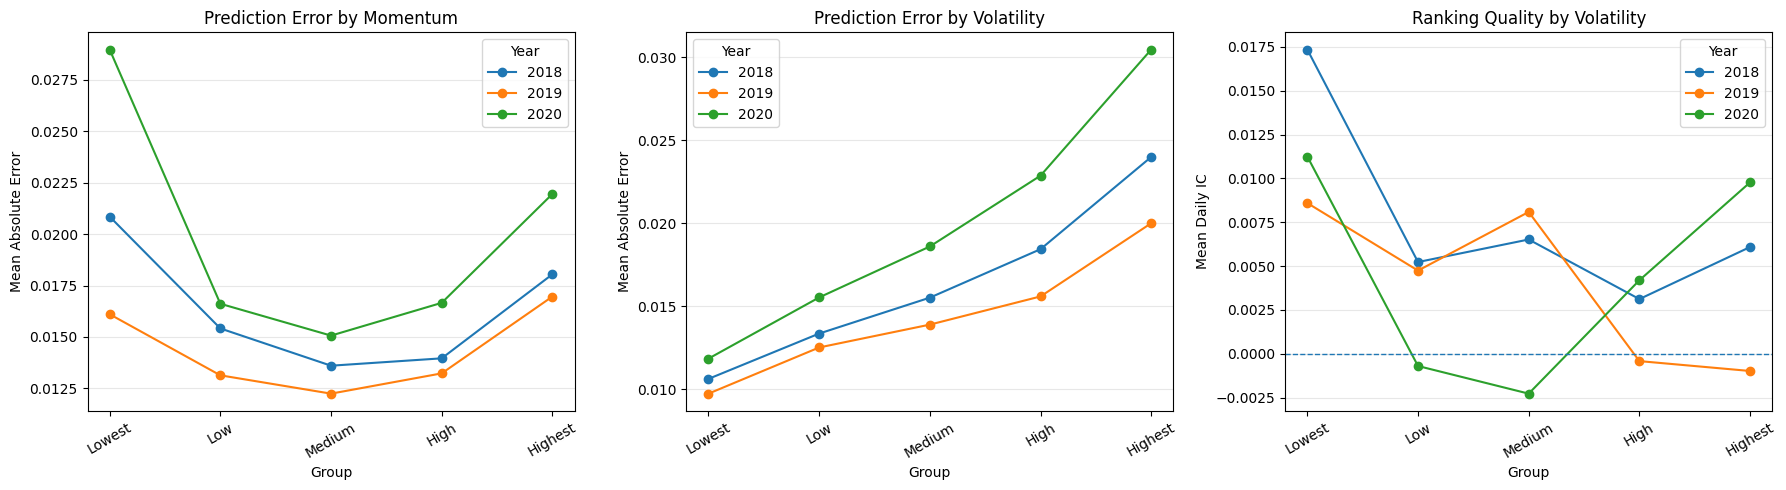

In [ ]:
import matplotlib.pyplot as plt

years = [2018, 2019, 2020]
groups = ["Lowest", "Low", "Medium", "High", "Highest"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Prediction error by momentum group
for year in years:
    data = group_summary[
        (group_summary["Year"] == year) &
        (group_summary["Type"] == "Momentum")
    ].copy()
    data["Group"] = pd.Categorical(
        data["Group"], categories=groups, ordered=True
    )
    data = data.sort_values("Group")
    axes[0].plot(
        data["Group"].astype(str),
        data["MeanAbsoluteError"],
        marker="o",
        label=str(year)
    )

axes[0].set_title("Prediction Error by Momentum")
axes[0].set_ylabel("Mean Absolute Error")
axes[0].legend(title="Year")

# 2. Prediction error by volatility group
for year in years:
    data = group_summary[
        (group_summary["Year"] == year) &
        (group_summary["Type"] == "Volatility")
    ].copy()
    data["Group"] = pd.Categorical(
        data["Group"], categories=groups, ordered=True
    )
    data = data.sort_values("Group")
    axes[1].plot(
        data["Group"].astype(str),
        data["MeanAbsoluteError"],
        marker="o",
        label=str(year)
    )

axes[1].set_title("Prediction Error by Volatility")
axes[1].set_ylabel("Mean Absolute Error")
axes[1].legend(title="Year")

# 3. Ranking quality by volatility group
for year in years:
    data = volatility_ic_summary[
        volatility_ic_summary["Year"] == year
    ].copy()
    data["VolatilityGroup"] = pd.Categorical(
        data["VolatilityGroup"], categories=groups, ordered=True
    )
    data = data.sort_values("VolatilityGroup")
    axes[2].plot(
        data["VolatilityGroup"].astype(str),
        data["MeanDailyIC"],
        marker="o",
        label=str(year)
    )

axes[2].axhline(0, linestyle="--", linewidth=1)
axes[2].set_title("Ranking Quality by Volatility")
axes[2].set_ylabel("Mean Daily IC")
axes[2].legend(title="Year")

for ax in axes:
    ax.set_xlabel("Group")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()